# AgentAccess

**Authors:** Alexander Michels

In [1]:
import access
import geopandas as gpd
from IPython.display import Image
import math
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from tqdm import tqdm
import sys
sys.path.append("../")
from agentaccess.Model import AgentAccess
# pandas gives warnings too often
pd.options.mode.chained_assignment = None

In [2]:
figsize=(10,10)

In [3]:
pop = gpd.read_file("../data/svi/SVI2018_US_tract.shp")
pop = pop[pop["STCNTY"] == "17031"]
pop = pop.to_crs("EPSG:4326")
print(len(pop))
pop.head()

1318


,ST,STATE,ST_ABBR,STCNTY,COUNTY,FIPS,LOCATION,AREA_SQMI,E_TOTPOP,M_TOTPOP,...,F_THEME4,F_TOTAL,E_UNINSUR,M_UNINSUR,EP_UNINSUR,MP_UNINSUR,E_DAYPOP,Shape_STAr,Shape_STLe,geometry
184,17,ILLINOIS,IL,17031,Cook,17031381700,"Census Tract 3817, Cook County, Illinois",0.075986,0,11,...,-999,-999,0,11,-999.0,-999.0,551,0.000021,0.020359,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
185,17,ILLINOIS,IL,17031,Cook,17031980000,"Census Tract 9800, Cook County, Illinois",7.679554,0,11,...,-999,-999,0,11,-999.0,-999.0,38202,0.002171,0.222431,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
186,17,ILLINOIS,IL,17031,Cook,17031980100,"Census Tract 9801, Cook County, Illinois",1.151272,0,11,...,-999,-999,0,11,-999.0,-999.0,6449,0.000323,0.076961,"POLYGON ((-87.76230 41.79274, -87.75251 41.792..."
12180,17,ILLINOIS,IL,17031,Cook,17031020100,"Census Tract 201, Cook County, Illinois",0.158747,3836,361,...,0,0,569,245,14.8,6.3,3714,0.000044,0.027301,"POLYGON ((-87.69020 42.01682, -87.69020 42.017..."
12181,17,ILLINOIS,IL,17031,Cook,17031020200,"Census Tract 202, Cook County, Illinois",0.479524,6739,510,...,0,1,628,396,9.3,6.0,3249,0.000135,0.051852,"POLYGON ((-87.70875 42.01550, -87.70866 42.019..."


In [4]:
pop["vehicle"] = pop["E_TOTPOP"] - pop["E_NOVEH"]

In [5]:
for x in pop["vehicle"]:
    assert x >= 0

In [6]:
# load the hospitals
hos = gpd.read_file("../data/hospitals/ContinentalHospitals.shp")
hos = hos[(hos["STATE"] == "IL") & (hos["COUNTY"] == "COOK")]
hos = hos[hos["BEDS"] >= 0]
print(sum(hos["BEDS"]))
hos = hos.to_crs("EPSG:4326")
print(len(hos))
hos.head()

18259
66


,OBJECTID,ID,NAME,ADDRESS,CITY,STATE,ZIP,ZIP4,TELEPHONE,TYPE,...,WEBSITE,STATE_ID,ALT_NAME,ST_FIPS,OWNER,TTL_STAFF,BEDS,TRAUMA,HELIPAD,geometry
507,1513,0003460644,UHS HARTGROVE HOSPITAL,5730 WEST ROOSEVELT ROAD,CHICAGO,IL,60644,NOT AVAILABLE,(773) 413-1700,PSYCHIATRIC,...,http://www.hartgrovehospital.com,0005454,NOT AVAILABLE,17,PROPRIETARY,-999,128,NOT AVAILABLE,N,POINT (-87.76746 41.86633)
508,1514,0001860612,JESSE BROWN VA MEDICAL CENTER - VA CHICAGO HEA...,820 S DAMEN STREET,CHICAGO,IL,60612,NOT AVAILABLE,(312) 569-8387,MILITARY,...,http://www.chicago.va.gov/,14003F,NOT AVAILABLE,17,GOVERNMENT - FEDERAL,-999,240,NOT AVAILABLE,N,POINT (-87.67704 41.87074)
509,1515,0003160463,PALOS COMMUNITY HOSPITAL,12251 SOUTH 80TH AVENUE,PALOS HEIGHTS,IL,60464,NOT AVAILABLE,(708) 923-4000,GENERAL ACUTE CARE,...,http://www.paloscommunityhospital.org,140062,NOT AVAILABLE,17,NON-PROFIT,-999,377,NOT AVAILABLE,Y,POINT (-87.81344 41.66921)
510,1516,0003660628,ROSELAND COMMUNITY HOSPITAL,45 W 111TH STREET,CHICAGO,IL,60628,NOT AVAILABLE,(773) 995-3000,GENERAL ACUTE CARE,...,http://www.roselandhospital.org,140068,NOT AVAILABLE,17,NON-PROFIT,-999,115,NOT AVAILABLE,N,POINT (-87.62536 41.69223)
511,1517,0002360302,WEST SUBURBAN MEDICAL CENTER,3 ERIE COURT,OAK PARK,IL,60302,NOT AVAILABLE,(708) 383-6200,GENERAL ACUTE CARE,...,http://www.westsuburbanmc.com/Home.aspx,140049,NOT AVAILABLE,17,PROPRIETARY,-999,172,NOT AVAILABLE,N,POINT (-87.77618 41.89140)


<AxesSubplot:>

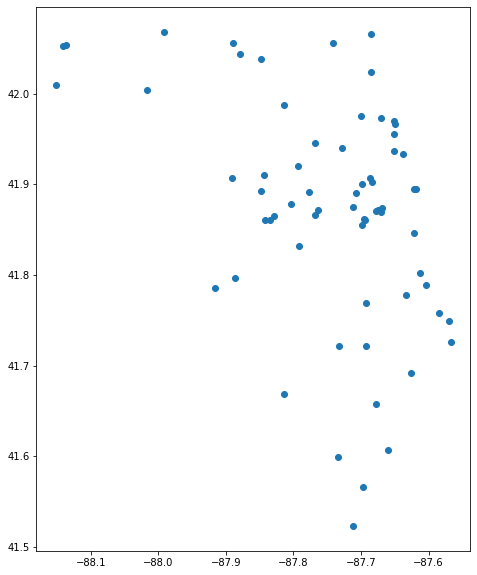

In [7]:
hos.plot(figsize=figsize)

In [8]:
# get car travel times
car = pd.read_csv("../data/travel_times/17031-output-TRACT-CAR.csv")
car["origin"] = car["origin"].astype(str)
car["destination"] = car["destination"].astype(str)
car = car.rename(columns={"minutes": "car"})
print(len(car))
car.head()

3780024


,origin,destination,car
0,17031010100,17007010100,101.35
1,17031010100,17007010200,96.10
2,17031010100,17007010300,96.43
3,17031010100,17007010400,96.17
4,17031010100,17007010500,107.13


In [9]:
# get the transit/walking times
transit = pd.read_csv("../data/travel_times/17031-output-TRACT-TRANSIT,WALK.csv")
transit["origin"] = transit["origin"].astype(str)
transit["destination"] = transit["destination"].astype(str)
transit = transit.rename(columns={"minutes": "transit"})
print(len(transit))
transit.head()

2853575


,origin,destination,transit
0,17031010100,17007010100,541.58
1,17031010100,17007010200,542.43
2,17031010100,17007010300,561.87
3,17031010100,17007010400,567.78
4,17031010100,17007010500,534.08


In [10]:
# get the walking times
walk = pd.read_csv("../data/travel_times/17031-output-TRACT-WALK.csv")
walk["origin"] = walk["origin"].astype(str)
walk["destination"] = walk["destination"].astype(str)
walk = walk.rename(columns={"minutes": "walk"})
print(len(walk))
walk.head()

234772


,origin,destination,walk
0,17031010100,17031010100,0.17
1,17031010100,17031010201,19.35
2,17031010100,17031010202,10.35
3,17031010100,17031010300,10.83
4,17031010100,17031010400,29.22


In [11]:
travel_times = pd.merge(car, transit, how="outer",
                       left_on=["origin", "destination"],
                       right_on=["origin", "destination"])
print(len(travel_times))
travel_times.head()

3782602


,origin,destination,car,transit
0,17031010100,17007010100,101.35,541.58
1,17031010100,17007010200,96.10,542.43
2,17031010100,17007010300,96.43,561.87
3,17031010100,17007010400,96.17,567.78
4,17031010100,17007010500,107.13,534.08


In [12]:
travel_times = pd.merge(travel_times, walk, how="outer",
                       left_on=["origin", "destination"],
                       right_on=["origin", "destination"])
print(len(travel_times))
travel_times.head()

3782602


,origin,destination,car,transit,walk
0,17031010100,17007010100,101.35,541.58,NaN
1,17031010100,17007010200,96.10,542.43,NaN
2,17031010100,17007010300,96.43,561.87,NaN
3,17031010100,17007010400,96.17,567.78,NaN
4,17031010100,17007010500,107.13,534.08,NaN


In [13]:
time_steps = 10

In [14]:
# intialize our model
# def __init__(self, demand_df, demand_geoid, demand_field, supply_df, supply_geoid, supply_field,
#              cost_df, cost_origin, cost_dest, cost_field, time_steps, memory=0, pop_per_agent=1000, top_k=0):
model = AgentAccess(
    pop,
    "FIPS",
    "E_TOTPOP",
    hos,
    "who cares",
    "BEDS",
    travel_times,
    "origin",
    "destination",
    ["car", "transit"],
    time_steps,
    cost_function="raam",
#     cost_prop=[0.7, 0.2, 0.1],
    cost_prop_fields=["vehicle", "E_NOVEH"],
    memory=0,
    pop_per_agent=10,
    top_k=5,
    output_path="../outputs/"
)

In [15]:
model.run_model()

recording: 100%|█████████████████████| 523104/523104 [00:06<00:00, 81898.83it/s]


Total elapsed time: 187.6176314353943


recording: 100%|█████████████████████| 523104/523104 [00:06<00:00, 82406.01it/s]


Total elapsed time: 195.506085395813


recording: 100%|█████████████████████| 523104/523104 [00:06<00:00, 84148.88it/s]


Total elapsed time: 183.81030416488647


... (11 outputs left out)

Total elapsed time: 185.67735362052917


recording: 100%|█████████████████████| 523104/523104 [00:06<00:00, 81608.48it/s]


Total elapsed time: 187.1066882610321


Running Model: 100%|███████████████████████████| 10/10 [33:29<00:00, 200.96s/it]


In [16]:
model.cost_df.head()

car  transit    walk
origin      destination                        
17031010100 17031031000  21.53    35.05   75.35
            17031031300  21.02    30.28   81.10
            17031031400  21.70    37.02  102.52
            17031032100  22.13    26.77   95.38
            17031040300  19.10    40.37   90.75

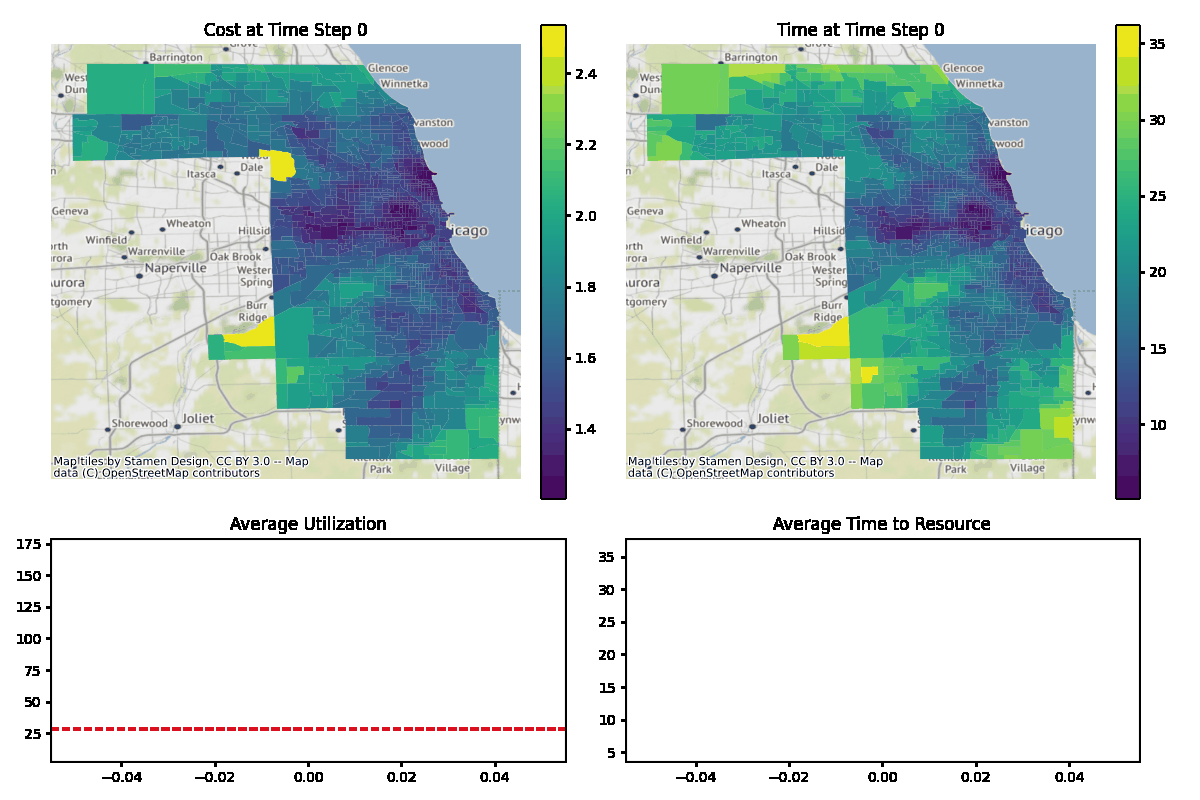

In [17]:
Image(filename=os.path.join(model.output_dir, "movie.gif"))

In [18]:
model.cost_df.head()

car  transit    walk
origin      destination                        
17031010100 17031031000  21.53    35.05   75.35
            17031031300  21.02    30.28   81.10
            17031031400  21.70    37.02  102.52
            17031032100  22.13    26.77   95.38
            17031040300  19.10    40.37   90.75

In [19]:
model.demand_df.head()

,ID,GEOID,Cost Field,Choice 0,Cost 0,Choice 1,Cost 1,Choice 2,Cost 2,Choice 3,...,Choice 5,Cost 5,Choice 6,Cost 6,Choice 7,Cost 7,Choice 8,Cost 8,Choice 9,Cost 9
0,0,17031381700,car,17031838100,1.611667,17031242400,1.161267,17031843300,1.430115,17031063303,...,17031841000,1.558728,17031838200,1.513134,17031838100,1.573961,17031838100,1.580316,17031841000,1.542166
1,1,17031980000,transit,17031100400,2.535667,17031811302,2.891563,17031151200,2.778992,17031241200,...,17031241200,3.076704,17031100400,2.611213,17031151200,3.165996,17031151200,3.165842,17031151200,3.163859
2,2,17031980100,car,17031822102,1.767667,17031838100,1.295978,17031815400,1.426685,17031840700,...,17031822102,1.596908,17031841000,1.706902,17031841000,1.740437,17031815400,1.789731,17031081401,1.734564
3,3,17031020100,car,17031810200,1.165000,17031838200,1.564382,17031808800,1.084962,17031808800,...,17031810200,1.137336,17031063303,1.695314,17031040300,1.593328,17031063303,1.699578,17031040300,1.590462
4,4,17031020100,car,17031031000,1.569333,17031810200,1.212010,17031810200,0.920324,17031810200,...,17031810200,1.137336,17031040300,1.586125,17031063303,1.704797,17031031000,1.707789,17031063303,1.702586


In [20]:
model.supply_df.head()

,geometry,Supply,Demand 0,D/S Ratio 0,Demand 1,D/S Ratio 1,Demand 2,D/S Ratio 2,Demand 3,D/S Ratio 3,...,Demand 5,D/S Ratio 5,Demand 6,D/S Ratio 6,Demand 7,D/S Ratio 7,Demand 8,D/S Ratio 8,Demand 9,D/S Ratio 9
GEOID,,,,,,,,,,,,,,,,,,,,,
17031031000,"POLYGON ((-87.67441 41.97610, -87.66961 41.976...",189,9817,51.941799,7.0,0.037037,7706.0,40.772487,3778.0,19.989418,...,4682,24.772487,5797,30.671958,6677,35.328042,5489,29.042328,6630,35.079365
17031031300,"POLYGON ((-87.65499 41.97640, -87.65428 41.976...",115,7699,66.947826,0.0,0.000000,370.0,3.217391,16147.0,140.408696,...,233,2.026087,1117,9.713043,3765,32.739130,3650,31.739130,3559,30.947826
17031031400,"POLYGON ((-87.65012 41.96916, -87.64964 41.969...",184,8557,46.505435,97.0,0.527174,7752.0,42.130435,3624.0,19.695652,...,3073,16.701087,6848,37.217391,4003,21.755435,6021,32.722826,5723,31.103261
17031032100,"POLYGON ((-87.65634 41.96176, -87.65475 41.961...",134,9222,68.820896,0.0,0.000000,1006.0,7.507463,11388.0,84.985075,...,5157,38.485075,3508,26.179104,4386,32.731343,4262,31.805970,4161,31.052239
17031040300,"POLYGON ((-87.70582 41.98309, -87.70401 41.983...",279,10094,36.179211,585.0,2.096774,19004.0,68.114695,2874.0,10.301075,...,9619,34.476703,8898,31.892473,8491,30.433692,8408,30.136201,8538,30.602151


In [21]:
model.spatial_units_df.head()

,Demand,geometry,Cost 0,D/S Ratio 0,Time 0,Cost 1,D/S Ratio 1,Time 1,Cost 2,D/S Ratio 2,...,Time 6,Cost 7,D/S Ratio 7,Time 7,Cost 8,D/S Ratio 8,Time 8,Cost 9,D/S Ratio 9,Time 9
GEOID,,,,,,,,,,,,,,,,,,,,,
17031381700,0,"POLYGON ((-87.62892 41.80919, -87.62608 41.809...",1.611667,13.569507,18.250000,1.161267,74.876268,23.950000,1.430115,71.989770,...,19.100000,1.573961,29.025411,18.250000,1.580316,24.856502,18.250000,1.542166,33.942993,12.650000
17031980000,0,"POLYGON ((-87.94025 42.00717, -87.93895 42.006...",2.535667,43.410448,21.070000,2.891563,50.254902,35.670000,2.778992,50.648746,...,21.070000,3.165996,30.867384,31.870000,3.165842,30.387097,31.870000,3.163859,30.225806,31.870000
17031980100,0,"POLYGON ((-87.76230 41.79274, -87.75251 41.792...",1.767667,14.059942,22.930000,1.295978,63.071749,24.570000,1.426685,44.660377,...,18.380000,1.740437,31.686461,18.380000,1.789731,27.091644,25.280000,1.734564,21.186504,25.370000
17031020100,3836,"POLYGON ((-87.69020 42.01682, -87.69020 42.017...",1.511928,37.446996,14.129193,1.237942,42.026117,21.400807,1.222965,38.396960,...,14.645000,1.470088,27.214859,14.990260,1.473281,26.340169,15.214323,1.479459,27.494689,14.983958
17031020200,6739,"POLYGON ((-87.70875 42.01550, -87.70866 42.019...",1.492527,32.065861,14.622003,1.232421,45.489408,23.021677,1.194621,38.804307,...,16.725772,1.469125,28.735324,14.884184,1.473432,27.282039,16.058042,1.480998,28.630393,15.191009


In [22]:
def normalize_columns(df, columns, to_flip=[]):
    for column in columns:
        df[column] = (df[column] - df[column].min()) / (df[column].max() - df[column].min())
        if column in to_flip:
            df[column] = 1 - df[column]
    return df

def average_columns(df, new_column, columns_to_average):
    df[new_column] = df[columns_to_average].mean(axis=1)
    return df

In [23]:
last_portion = 2
df = average_columns(model.spatial_units_df, "D/S Ratio", [f"D/S Ratio {x}" for x  in range(time_steps - (time_steps//last_portion), time_steps)])
df = average_columns(df, "Time", [f"Time {x}" for x  in range(time_steps - (time_steps//last_portion), time_steps)])
df = average_columns(df, "Cost", [f"Cost {x}" for x  in range(time_steps - (time_steps//last_portion), time_steps)])
df = df[["D/S Ratio", "Time", "Cost", "geometry"]]
df.head()

,D/S Ratio,Time,Cost,geometry
GEOID,,,,
17031381700,29.413248,16.180000,1.553661,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
17031980000,30.860263,30.262000,3.036723,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
17031980100,28.780459,22.068000,1.713708,"POLYGON ((-87.76230 41.79274, -87.75251 41.792..."
17031020100,27.308071,14.867234,1.470676,"POLYGON ((-87.69020 42.01682, -87.69020 42.017..."
17031020200,28.266741,15.783294,1.469623,"POLYGON ((-87.70875 42.01550, -87.70866 42.019..."


In [24]:
cols = ["D/S Ratio", "Time", "Cost"]
model_result = df
# model_result = normalize_columns(df, columns=cols)
model_result.head()

,D/S Ratio,Time,Cost,geometry
GEOID,,,,
17031381700,29.413248,16.180000,1.553661,"POLYGON ((-87.62892 41.80919, -87.62608 41.809..."
17031980000,30.860263,30.262000,3.036723,"POLYGON ((-87.94025 42.00717, -87.93895 42.006..."
17031980100,28.780459,22.068000,1.713708,"POLYGON ((-87.76230 41.79274, -87.75251 41.792..."
17031020100,27.308071,14.867234,1.470676,"POLYGON ((-87.69020 42.01682, -87.69020 42.017..."
17031020200,28.266741,15.783294,1.469623,"POLYGON ((-87.70875 42.01550, -87.70866 42.019..."


<AxesSubplot:>

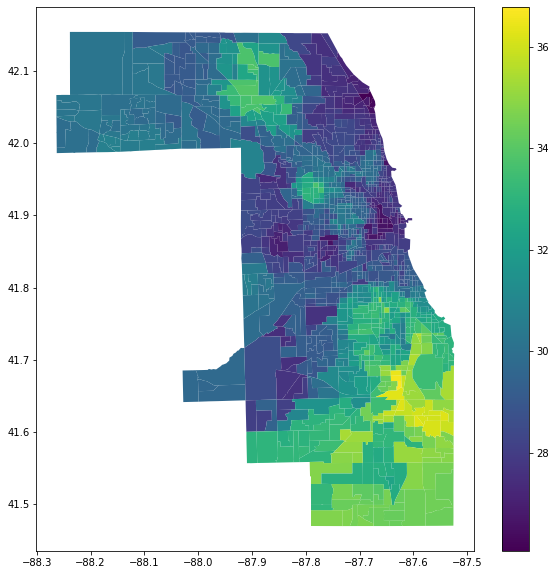

In [25]:
model_result.plot(column="D/S Ratio", figsize=figsize, legend=True)

<AxesSubplot:>

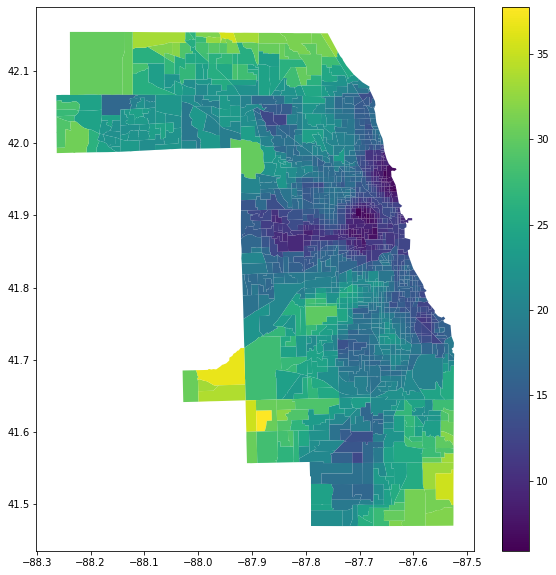

In [26]:
model_result.plot(column="Time", figsize=figsize, legend=True)

<AxesSubplot:>

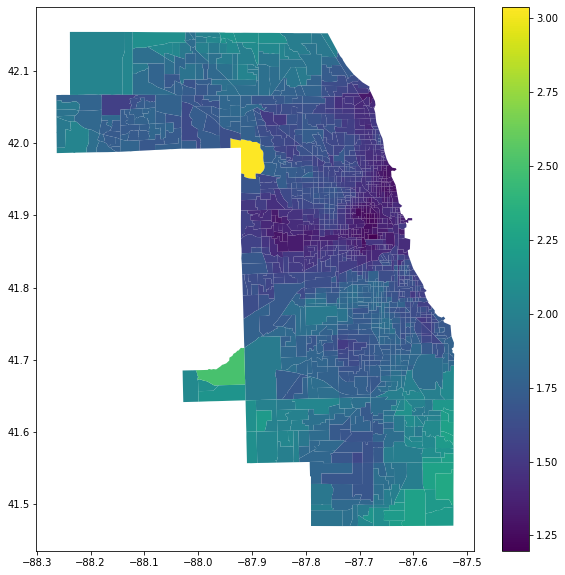

In [27]:
model_result.plot(column="Cost", figsize=figsize, legend=True)

In [28]:
acc = gpd.read_file("../data/accessibility/CookHospitals.gpkg")
acc = acc.set_index("geoid")
cols = list(acc.columns)
cols.remove('geometry')
# acc = normalize_columns(acc, cols)
print(len(acc))
acc.head()

1318


,gravity_BEDS,fca_BEDS,fca60_BEDS,fca90_BEDS,2sfca_BEDS,2sfca30_BEDS,2sfca60_BEDS,g2sfca_BEDS,3sfca_BEDS,raam_BEDS,raam30_BEDS,geometry
geoid,,,,,,,,,,,,
17031010100,28947.351633,0.005191,0.003693,0.003495,0.002790,0.003988,0.002484,0.002699,0.005337,1.151754,1.353203,"POLYGON ((-87.66507 42.01926, -87.66604 42.019..."
17031010201,30688.468786,0.004612,0.003705,0.003495,0.003022,0.004222,0.002714,0.002867,0.005148,1.115558,1.278645,"POLYGON ((-87.68281 42.01947, -87.68163 42.019..."
17031010202,29613.408700,0.004703,0.003669,0.003495,0.002956,0.004354,0.002645,0.002820,0.005539,1.173011,1.375311,"POLYGON ((-87.67464 42.01263, -87.67547 42.012..."
17031010300,29395.681764,0.004847,0.003738,0.003495,0.002931,0.004445,0.002648,0.002814,0.005940,1.187285,1.428868,"POLYGON ((-87.66383 42.01612, -87.66340 42.015..."
17031010400,31556.255500,0.004244,0.003601,0.003495,0.003050,0.002963,0.003023,0.003120,0.004095,1.126623,1.375371,"POLYGON ((-87.66156 42.01041, -87.66108 42.009..."


In [29]:
comparison = gpd.GeoDataFrame(df[["D/S Ratio", "Time", "Cost"]].merge(acc, left_index=True, right_index=True))
print(len(comparison))
comparison.head()

1318


,D/S Ratio,Time,Cost,gravity_BEDS,fca_BEDS,fca60_BEDS,fca90_BEDS,2sfca_BEDS,2sfca30_BEDS,2sfca60_BEDS,g2sfca_BEDS,3sfca_BEDS,raam_BEDS,raam30_BEDS,geometry
17031381700,29.413248,16.180000,1.553661,39837.372655,0.004058,0.003495,0.003495,0.003801,0.004707,0.004417,0.004737,0.003667,NaN,NaN,"POLYGON ((-87.62608 41.80924, -87.62603 41.807..."
17031980000,30.860263,30.262000,3.036723,28311.101254,0.002253,0.003604,0.003495,0.003613,0.000744,0.003538,0.002564,0.001266,NaN,NaN,"POLYGON ((-87.87787 41.97304, -87.87675 41.969..."
17031980100,28.780459,22.068000,1.713708,33166.883503,0.004231,0.003634,0.003495,0.003801,0.002793,0.003975,0.003692,0.002473,NaN,NaN,"POLYGON ((-87.74836 41.77831, -87.75322 41.778..."
17031020100,27.308071,14.867234,1.470676,31084.752206,0.004443,0.003671,0.003495,0.003123,0.004222,0.002825,0.002925,0.004924,1.110285,1.265311,"POLYGON ((-87.69023 42.01411, -87.69020 42.016..."
17031020200,28.266741,15.783294,1.469623,30644.100285,0.003132,0.003576,0.003495,0.003228,0.004036,0.003269,0.003030,0.004207,1.149850,1.340311,"POLYGON ((-87.69023 42.01411, -87.69025 42.012..."


In [30]:
corr = comparison.corr(method='pearson')
corr.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

,D/S Ratio,Time,Cost,gravity_BEDS,fca_BEDS,fca60_BEDS,fca90_BEDS,2sfca_BEDS,2sfca30_BEDS,2sfca60_BEDS,g2sfca_BEDS,3sfca_BEDS,raam_BEDS,raam30_BEDS
D/S Ratio,1.000000,0.345431,0.624933,-0.492924,-0.404652,0.361481,0.129124,-0.414938,-0.535379,-0.453510,-0.510041,-0.532295,0.574540,0.561296
Time,0.345431,1.000000,0.913805,-0.791552,-0.617553,0.443004,0.127840,-0.599688,-0.741220,-0.686602,-0.740464,-0.755246,0.900789,0.902924
Cost,0.624933,0.913805,1.000000,-0.790237,-0.603646,0.473738,0.158758,-0.604806,-0.787686,-0.690886,-0.759219,-0.806562,0.929669,0.928379
gravity_BEDS,-0.492924,-0.791552,-0.790237,1.000000,0.505141,-0.507826,-0.112050,0.673174,0.811063,0.792053,0.859635,0.604103,-0.810579,-0.803311
fca_BEDS,-0.404652,-0.617553,-0.603646,0.505141,1.000000,-0.381211,-0.056597,0.563385,0.521101,0.582382,0.583030,0.547938,-0.597256,-0.580058
fca60_BEDS,0.361481,0.443004,0.473738,-0.507826,-0.381211,1.000000,0.098476,-0.597425,-0.413258,-0.654259,-0.607977,-0.206730,0.428190,0.401780
fca90_BEDS,0.129124,0.127840,0.158758,-0.112050,-0.056597,0.098476,1.000000,-0.278139,-0.079728,-0.170018,-0.133935,-0.048237,0.077134,0.062819
2sfca_BEDS,-0.414938,-0.599688,-0.604806,0.673174,0.563385,-0.597425,-0.278139,1.000000,0.583306,0.909718,0.820181,0.329221,-0.572880,-0.549919
2sfca30_BEDS,-0.535379,-0.741220,-0.787686,0.811063,0.521101,-0.413258,-0.079728,0.583306,1.000000,0.769576,0.888566,0.791142,-0.772344,-0.776946
2sfca60_BEDS,-0.453510,-0.686602,-0.690886,0.792053,0.582382,-0.654259,-0.170018,0.909718,0.769576,1.000000,0.960267,0.438506,-0.661083,-0.643517


In [31]:
corr = comparison.corr(method='kendall')
corr.style.background_gradient(cmap='coolwarm', vmin=-1, vmax=1)

,D/S Ratio,Time,Cost,gravity_BEDS,fca_BEDS,fca60_BEDS,fca90_BEDS,2sfca_BEDS,2sfca30_BEDS,2sfca60_BEDS,g2sfca_BEDS,3sfca_BEDS,raam_BEDS,raam30_BEDS
D/S Ratio,1.000000,0.258825,0.462451,-0.355057,-0.258316,0.294424,0.108688,-0.332059,-0.384228,-0.312121,-0.345266,-0.392669,0.420201,0.409801
Time,0.258825,1.000000,0.743395,-0.665483,-0.427786,0.314508,0.122652,-0.448145,-0.556068,-0.463500,-0.530263,-0.571325,0.728666,0.729232
Cost,0.462451,0.743395,1.000000,-0.669023,-0.424330,0.366705,0.131560,-0.492459,-0.614249,-0.492082,-0.561912,-0.636240,0.776292,0.772836
gravity_BEDS,-0.355057,-0.665483,-0.669023,1.000000,0.418928,-0.451956,-0.142672,0.678072,0.648677,0.740050,0.797307,0.481011,-0.663228,-0.656957
fca_BEDS,-0.258316,-0.427786,-0.424330,0.418928,1.000000,-0.240970,-0.070710,0.403864,0.361909,0.325709,0.375433,0.387962,-0.422593,-0.403532
fca60_BEDS,0.294424,0.314508,0.366705,-0.451956,-0.240970,1.000000,0.094149,-0.391995,-0.365058,-0.476591,-0.487398,-0.227840,0.325052,0.318597
fca90_BEDS,0.108688,0.122652,0.131560,-0.142672,-0.070710,0.094149,1.000000,-0.152429,-0.096347,-0.143052,-0.138186,-0.045983,0.096019,0.082770
2sfca_BEDS,-0.332059,-0.448145,-0.492459,0.678072,0.403864,-0.391995,-0.152429,1.000000,0.539095,0.791292,0.748613,0.341379,-0.468534,-0.450638
2sfca30_BEDS,-0.384228,-0.556068,-0.614249,0.648677,0.361909,-0.365058,-0.096347,0.539095,1.000000,0.608575,0.695556,0.645446,-0.589144,-0.594076
2sfca60_BEDS,-0.312121,-0.463500,-0.492082,0.740050,0.325709,-0.476591,-0.143052,0.791292,0.608575,1.000000,0.869841,0.333898,-0.464624,-0.449428


<AxesSubplot:>

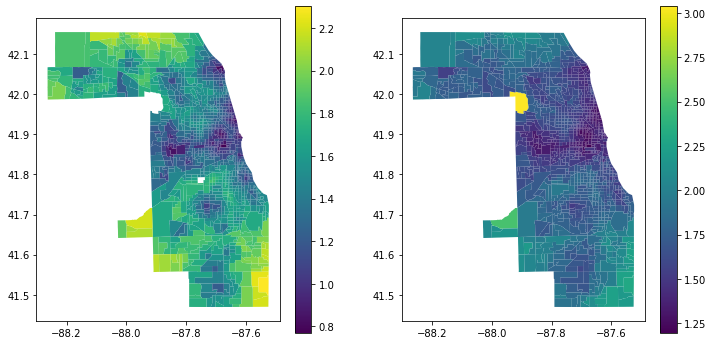

In [32]:
field1, field2 = "raam30_BEDS", "Cost"
figs, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
comparison.plot(ax=ax1, column=field1, legend=True)
comparison.plot(ax=ax2, column=field2, legend=True)

<AxesSubplot:>

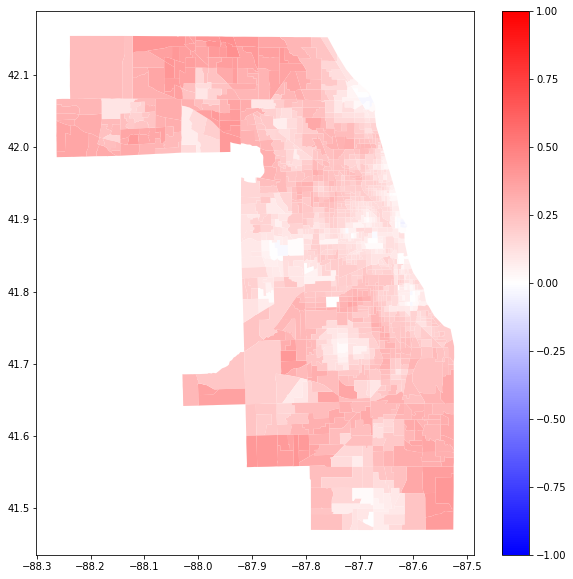

In [33]:
x = normalize_columns(comparison, [field1, field2])
x["Compare"] = x[field1] - x[field2]
x.plot(column="Compare", cmap="bwr", figsize=figsize, legend=True, vmin=-1, vmax=1)